# Predictive Churn Analysis
Logistic Regression vs Random Forest. Run all cells. In Colab, upload `customer_churn_model_v2.csv` when prompted (or place it in `data/`).

In [1]:
from pathlib import Path
import os
Path('data').mkdir(exist_ok=True)
if not Path('data/customer_churn_model_v2.csv').exists():
    from google.colab import files
    up = files.upload()
    os.replace(next(iter(up)), 'data/customer_churn_model_v2.csv')

In [2]:
import json
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

SEED = 42
ROOT = Path(".")
OUT = ROOT / "outputs"; OUT.mkdir(exist_ok=True)

## 1. Load + validate

In [3]:
# 1. Load + validate ---------------------------------------------------------
df = pd.read_csv(ROOT / "data" / "customer_churn_model_v2.csv")
assert df.CustomerID.is_unique and df.isna().sum().sum() == 0
y = (df.Churn == "Yes").astype(int)
X = df.drop(columns=["CustomerID", "Churn"])
num = X.select_dtypes("number").columns.tolist()
cat = X.select_dtypes(exclude="number").columns.tolist()

## 2. Feature encoding: One-Hot for categoricals, MinMax scaling for numerics

In [4]:
# 2. Feature encoding: One-Hot for categoricals, MinMax scaling for numerics ---
prep = ColumnTransformer([("num", MinMaxScaler(), num),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

## 3. 80/20 stratified split

In [5]:
# 3. 80/20 stratified split ---------------------------------------------------
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

## 4. Train two models; tune with 5-fold CV on the TRAIN set only

In [6]:
# 4. Train two models; tune with 5-fold CV on the TRAIN set only ---------------
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
models = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=SEED), {"clf__C": [0.1, 1, 10]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED), {"clf__n_estimators": [200, 400], "clf__max_depth": [4, 8, None], "clf__min_samples_leaf": [1, 5]}),
}
fitted, rows = {}, []
for name, (clf, grid) in models.items():
    gs = GridSearchCV(Pipeline([("prep", prep), ("clf", clf)]), grid, scoring="roc_auc", cv=cv, n_jobs=-1).fit(X_tr, y_tr)
    prob = gs.predict_proba(X_te)[:, 1]; pred = (prob >= 0.5).astype(int)
    fitted[name] = (gs.best_estimator_, prob)
    rows.append({"Model": name, "CV ROC-AUC (train)": round(gs.best_score_, 4), "Accuracy": accuracy_score(y_te, pred),
                 "Precision": precision_score(y_te, pred), "Recall": recall_score(y_te, pred),
                 "F1": f1_score(y_te, pred), "ROC-AUC (test)": roc_auc_score(y_te, prob), "Best params": str(gs.best_params_)})
res = pd.DataFrame(rows).round(4); res.to_csv(OUT / "model_comparison.csv", index=False)
print(res.drop(columns="Best params").to_string(index=False))

# Best model chosen by cross-validated AUC on train data (test set stays untouched)
best = res.sort_values("CV ROC-AUC (train)", ascending=False).iloc[0].Model
pipe, prob_te = fitted[best]; print("Selected model:", best)

              Model  CV ROC-AUC (train)  Accuracy  Precision  Recall     F1  ROC-AUC (test)
Logistic Regression              0.6987    0.6438     0.5862  0.5075 0.5440          0.6832
      Random Forest              0.7209    0.6500     0.5775  0.6119 0.5942          0.6838
Selected model: Random Forest


## 5. Plots

In [7]:
# 5. Plots ---------------------------------------------------------------------
plt.figure(figsize=(6, 5))
for name, (_, p) in fitted.items():
    fpr, tpr, _ = roc_curve(y_te, p); plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC={roc_auc_score(y_te, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curve (20% test set)"); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(OUT / "roc_curve.png", dpi=150); plt.close()
ConfusionMatrixDisplay.from_predictions(y_te, (prob_te >= .5).astype(int), display_labels=["Stayed", "Churned"], cmap="Blues"); plt.title(f"Confusion matrix - {best}"); plt.tight_layout()
plt.savefig(OUT / "confusion_matrix.png", dpi=150); plt.close()

names = pipe.named_steps["prep"].get_feature_names_out()
clf = pipe.named_steps["clf"]
imp = pd.Series(clf.coef_[0] if hasattr(clf, "coef_") else clf.feature_importances_, index=names)
imp.index = imp.index.str.replace("num__", "").str.replace("cat__", "")
top = imp.reindex(imp.abs().sort_values(ascending=False).index)[:12]
top.to_csv(OUT / "feature_importance.csv", header=["value"])
plt.figure(figsize=(7, 5)); top[::-1].plot.barh(color="#3b6fd4"); plt.title("Top drivers (" + ("coefficients" if hasattr(clf, "coef_") else "importance") + f") - {best}"); plt.tight_layout()
plt.savefig(OUT / "feature_importance.png", dpi=150); plt.close()

## 6. Export churn risk scores for every customer

In [8]:
# 6. Export churn risk scores for every customer ------------------------------
score = pd.DataFrame({"CustomerID": df.CustomerID, "ChurnRiskScore": pipe.predict_proba(X)[:, 1].round(4)})
score["RiskBand"] = pd.cut(score.ChurnRiskScore, [-.01, .33, .66, 1], labels=["Low", "Medium", "High"])
score["PredictedChurn"] = np.where(score.ChurnRiskScore >= .5, "Yes", "No"); score["ActualChurn"] = df.Churn
score["Split"] = np.where(score.index.isin(X_te.index), "test", "train")
score.sort_values("ChurnRiskScore", ascending=False).to_csv(OUT / "churn_risk_scores.csv", index=False)

pd.Series({"selected_model": best, "n_train": len(X_tr), "n_test": len(X_te), "churn_rate": float(y.mean())}).to_json(OUT / "run_summary.json")
print(score.groupby("Split").RiskBand.value_counts().unstack())
print(top.round(3).to_string())

RiskBand  Low  Medium  High
Split                      
test       62      97     1
train     259     376     5
ContractType_Month-to-Month    0.241
LatePayments                   0.141
ContractType_One Year          0.092
TenureMonths                   0.079
ContractType_Two Year          0.075
TotalChargesINR                0.070
MonthlyChargesINR              0.069
SupportTickets                 0.068
Age                            0.052
Region_South                   0.019
AutoPay_Yes                    0.011
Region_West                    0.010


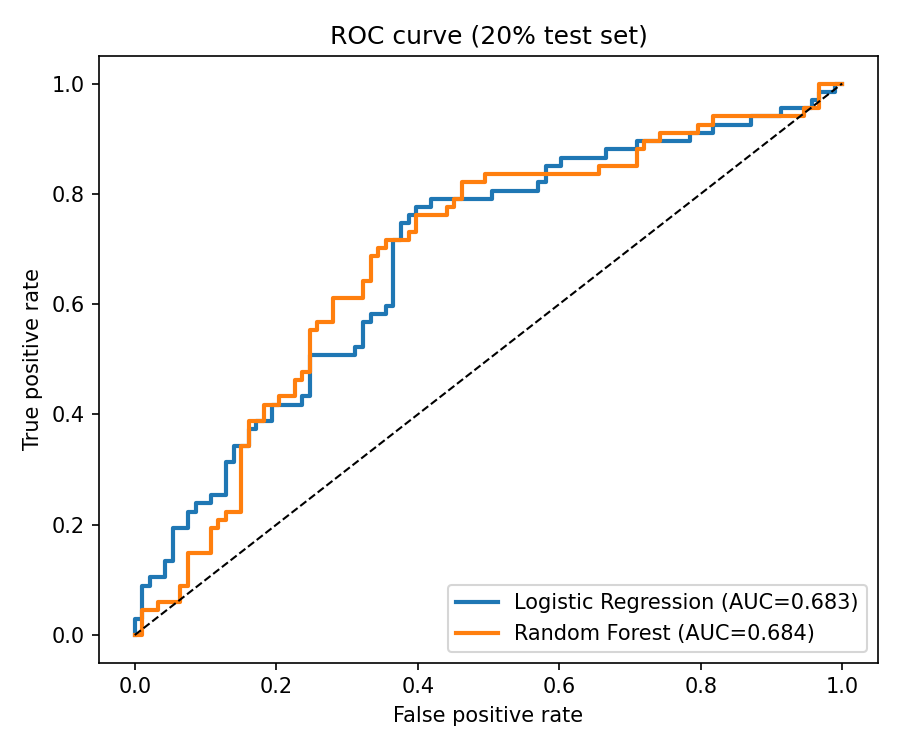

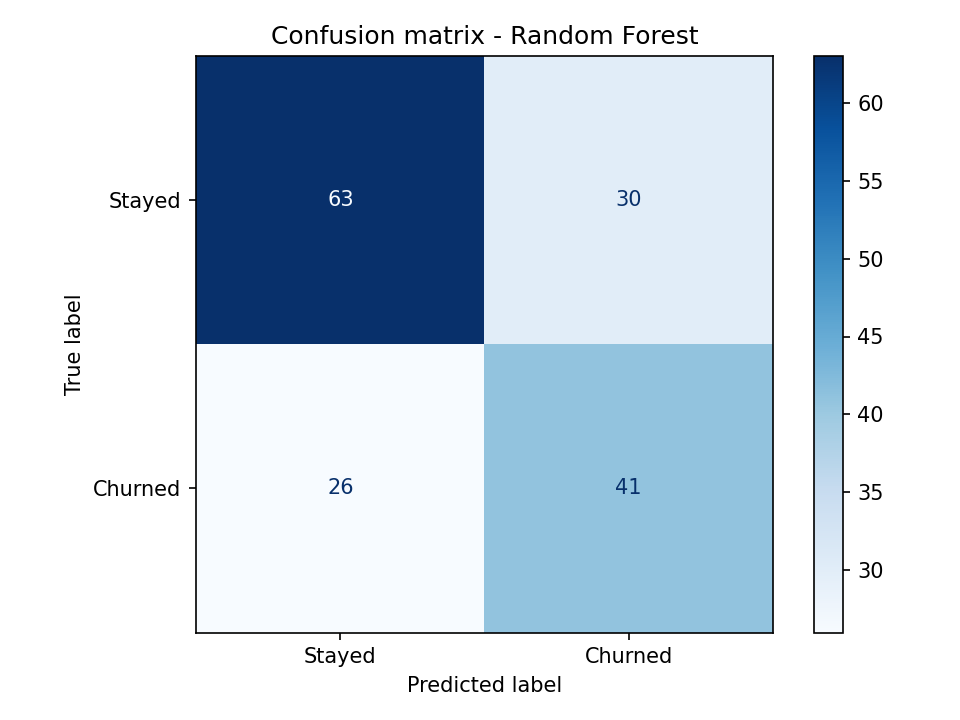

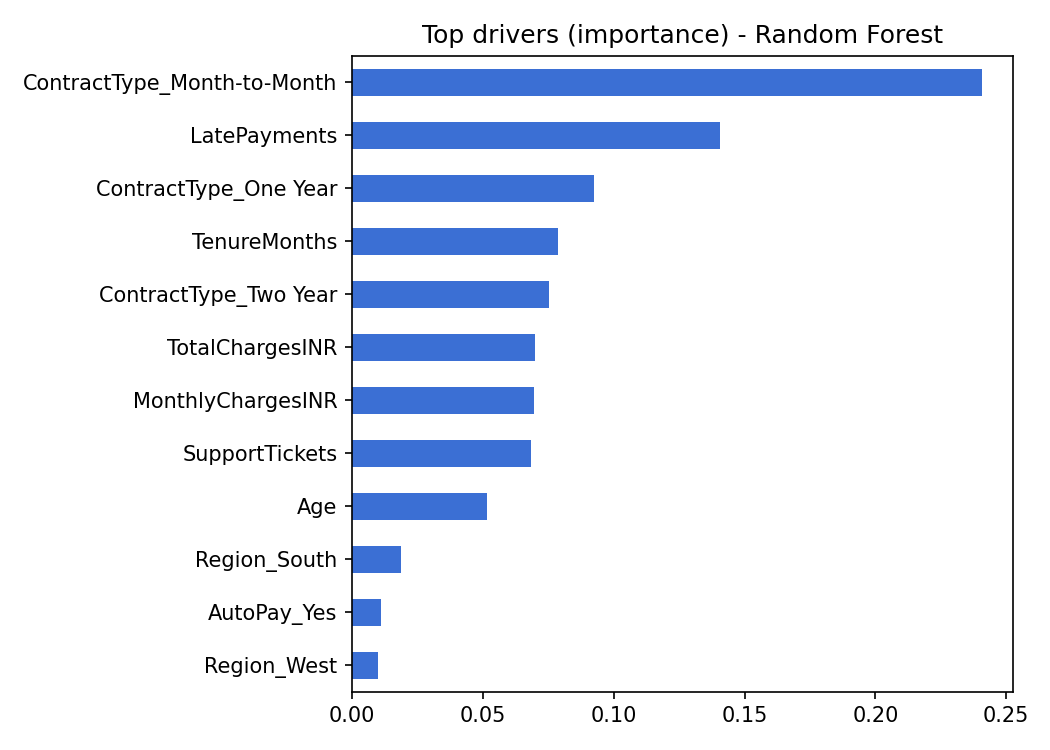

In [9]:
from IPython.display import Image, display
for f in ['roc_curve','confusion_matrix','feature_importance']:
    display(Image(f'outputs/{f}.png'))